# 05 — Model Training: AI Analisis Kendala Way2Home

Notebook ini melatih, men-tuning, mengevaluasi, menjelaskan, dan mengekspor tiga model:

| # | Tugas | File | Target | Jenis | Metrik utama |
|---|---|---|---|---|---|
| 1 | Risk Classification | `way2home_risk_classification.csv` | `risk_level` (LOW/MEDIUM/HIGH) | Klasifikasi multikelas | **Macro F1** |
| 2 | Delay Regression | `way2home_delay_regression.csv` | `delay_days` | Regresi | **MAE** (hari) |
| 3 | Cost Prediction | `way2home_cost_prediction.csv` | `cost_overrun` (rasio) | Regresi | **MAE** (poin rasio) |

Audit dan harmonisasi **tidak** diulang di sini (lihat notebook 01 dan 02).

**Algoritma:** Logistic/Linear Regression (baseline), Random Forest, XGBoost, CatBoost. Sebagai rujukan ditambahkan *Dummy* (tebakan naif) dan *HistGradientBoosting* dari scikit-learn. XGBoost dan CatBoost **hanya dilatih jika library-nya terpasang**. Jika tidak, keduanya dicatat sebagai `SKIPPED` dan notebook tetap berjalan.

**Keterbatasan yang harus diingat sepanjang notebook:** semua data training **sintetis** dan dicatat per **proyek**, bukan per kejadian kendala. Performa di sini **tidak** membuktikan model siap untuk proyek rumah nyata.

## 1. Import libraries & konfigurasi eksperimen
Seluruh konfigurasi (seed, ukuran test, jumlah fold, jumlah iterasi tuning) dicatat di satu tempat dan disimpan ke metadata.

In [1]:
import sys, json, time, platform, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, sklearn

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import (StratifiedGroupKFold, GroupKFold, RandomizedSearchCV, cross_val_score)
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import (RandomForestClassifier, RandomForestRegressor,
                              HistGradientBoostingClassifier, HistGradientBoostingRegressor)
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix,
                             classification_report, mean_absolute_error, mean_squared_error, r2_score)
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.inspection import permutation_importance, partial_dependence
from scipy.stats import loguniform

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60); pd.set_option("display.max_colwidth", 80)

# ---------- Path relatif dari root project ----------
def find_project_root(start: Path = Path.cwd()) -> Path:
    for p in [start, *start.parents]:
        if (p / "data" / "final").is_dir():
            return p
    raise FileNotFoundError("Folder data/final tidak ditemukan. Jalankan notebook di dalam folder project.")
ROOT = find_project_root()
FINAL, MODELS, REPORTS = ROOT / "data/final", ROOT / "models", ROOT / "reports"
FIG = REPORTS / "figures"
for d in (MODELS, MODELS / "candidates", REPORTS, FIG):
    d.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "src"))
from w2h_ml import ClippedRegressor, Way2HomeKendalaPredictor, way2home_input_to_features

# ---------- Library opsional ----------
def try_import(name):
    try:
        mod = __import__(name)
        return mod, getattr(mod, "__version__", "unknown")
    except Exception:
        return None, "NOT INSTALLED"
xgb, XGB_VER = try_import("xgboost")
cb, CB_VER = try_import("catboost")
shap, SHAP_VER = try_import("shap")
HAS_XGB, HAS_CB, HAS_SHAP = xgb is not None, cb is not None, shap is not None

# ---------- Konfigurasi eksperimen ----------
CONFIG = {
    "random_state": 42,
    "test_size": 0.20,                 # 1 dari 5 fold StratifiedGroupKFold = 20%
    "cv_folds": 5,
    "n_iter_search": 12,               # pencarian sedang: data 4.000 baris training, 12 fitur
    "n_jobs": -1,
    "permutation_repeats": 10,
    "bootstrap_iterations": 1000,
    "class_order": ["LOW", "MEDIUM", "HIGH"],
    "primary_metric": {"risk_classification": "f1_macro", "delay_regression": "MAE", "cost_prediction": "MAE"},
}
SEED = CONFIG["random_state"]
np.random.seed(SEED)

VERSIONS = {"python": platform.python_version(), "numpy": np.__version__, "pandas": pd.__version__,
            "scikit-learn": sklearn.__version__, "joblib": joblib.__version__,
            "xgboost": XGB_VER, "catboost": CB_VER, "shap": SHAP_VER}
print("Project root:", ROOT)
print(json.dumps(VERSIONS, indent=1))

# Palet grafik (urutan kategorikal tetap; biru = seri utama)
C_MAIN, C_ACCENT, C_GRAY = "#2a78d6", "#eb6834", "#9a9a9a"
C_CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e5e5e5", "axes.axisbelow": True})
def savefig(fig, name):
    fig.savefig(FIG / name, bbox_inches="tight", dpi=150)

Project root: /home/claude/way2home
{
 "python": "3.13.18",
 "numpy": "2.5.3",
 "pandas": "3.0.5",
 "scikit-learn": "1.9.1",
 "joblib": "1.6.0",
 "xgboost": "NOT INSTALLED",
 "catboost": "NOT INSTALLED",
 "shap": "NOT INSTALLED"
}


## 2. Load dataset
Kolom berawalan `meta_` adalah kolom pelacakan dan **tidak pernah** dipakai sebagai fitur.

In [2]:
TASK_FILES = {"risk_classification": "way2home_risk_classification.csv",
              "delay_regression": "way2home_delay_regression.csv",
              "cost_prediction": "way2home_cost_prediction.csv"}
TASK_TARGET = {"risk_classification": "risk_level", "delay_regression": "delay_days", "cost_prediction": "cost_overrun"}
OTHER_TARGETS = {"overbudget_flag", "risk_level", "delay_days", "cost_overrun", "delay_risk_binary"}

data = {t: pd.read_csv(FINAL / f) for t, f in TASK_FILES.items()}
master = pd.read_csv(FINAL / "way2home_kendala_training.csv")
for t, df in data.items():
    print(f"{t:22s} {df.shape}  target={TASK_TARGET[t]}")
print("Master dataset:", master.shape)

risk_classification    (5000, 18)  target=risk_level
delay_regression       (5000, 18)  target=delay_days
cost_prediction        (5000, 19)  target=cost_overrun
Master dataset: (6000, 57)


## 3. Validasi fitur & target
Yang dicek:
- Target tidak kosong dan labelnya valid.
- Tidak ada kolom identitas, sumber, atau target lain di antara fitur.
- Kondisi missing values.
- Komposisi sumber dan status sintetis.
- Apakah ketiga subset berisi proyek yang sama. Ini menentukan strategi split.

In [3]:
FORBIDDEN = {"source_dataset", "source_record_id", "is_synthetic", "project_group_id", "record_uid",
             "data_granularity", "lokasi", "mata_uang", "biaya_aktual", "cost_overrun_amount", "cost_overrun_ratio"}
FEATURES, META = {}, {}
for t, df in data.items():
    meta_cols = [c for c in df.columns if c.startswith("meta_")]
    feats = [c for c in df.columns if c not in meta_cols and c not in OTHER_TARGETS]
    bad = set(feats) & (FORBIDDEN | OTHER_TARGETS)
    assert not bad, f"{t}: kolom terlarang di fitur {bad}"
    y = df[TASK_TARGET[t]]
    n_before = len(df)
    data[t] = df = df[y.notna()].reset_index(drop=True)          # target tidak diimputasi; baris tanpa target dibuang
    FEATURES[t], META[t] = feats, meta_cols
    print(f"\n=== {t}: {len(df)} baris (dibuang karena target kosong: {n_before - len(df)}) | {len(feats)} fitur")
    print("fitur:", feats)
    miss = df[feats].isna().sum()
    print("missing pada fitur:", miss[miss > 0].to_dict() or "tidak ada")
    print("sumber:", df.meta_source_dataset.value_counts().to_dict(), "| sintetis:", df.meta_is_synthetic.value_counts().to_dict())

assert set(data["risk_classification"].risk_level) <= set(CONFIG["class_order"])
assert (data["delay_regression"].delay_days >= 0).all()
print("\nDistribusi risk_level:", data["risk_classification"].risk_level.value_counts().reindex(CONFIG["class_order"]).to_dict())

# Ketiga subset berasal dari proyek yang sama?
gsets = {t: set(df.meta_project_group_id) for t, df in data.items()}
same_projects = gsets["risk_classification"] == gsets["delay_regression"] == gsets["cost_prediction"]
print("Ketiga subset berisi proyek yang sama:", same_projects)
print("Record per proyek (maks):", max(df.meta_project_group_id.value_counts().max() for df in data.values()))
print("Fitur sama di ketiga subset:", FEATURES["risk_classification"] == FEATURES["delay_regression"] == FEATURES["cost_prediction"])


=== risk_classification: 5000 baris (dibuang karena target kosong: 0) | 12 fitur
fitur: ['flag_kendala_material', 'flag_kendala_cuaca', 'flag_kendala_keselamatan', 'dampak_waktu_hari', 'dampak_waktu_material_hari', 'dampak_waktu_cuaca_hari', 'estimasi_biaya', 'durasi_proyek_hari', 'progress_persen', 'jumlah_pekerja', 'utilisasi_peralatan_persen', 'jumlah_insiden_keselamatan']
missing pada fitur: tidak ada
sumber: {'CONSTRUCTION_DELAY_RISK_GH': 5000} | sintetis: {True: 5000}

=== delay_regression: 5000 baris (dibuang karena target kosong: 0) | 12 fitur
fitur: ['flag_kendala_material', 'flag_kendala_cuaca', 'flag_kendala_keselamatan', 'dampak_waktu_hari', 'dampak_waktu_material_hari', 'dampak_waktu_cuaca_hari', 'estimasi_biaya', 'durasi_proyek_hari', 'progress_persen', 'jumlah_pekerja', 'utilisasi_peralatan_persen', 'jumlah_insiden_keselamatan']
missing pada fitur: tidak ada
sumber: {'CONSTRUCTION_DELAY_RISK_GH': 5000} | sintetis: {True: 5000}

=== cost_prediction: 5000 baris (dibuang k

**Interpretasi:**
- Ketiga subset berisi **5.000 proyek yang sama** dari satu sumber (CONSTRUCTION_DELAY_RISK_GH), dengan 12 fitur numerik yang sama dan tanpa missing value.
- Setiap proyek hanya punya satu baris, jadi split per proyek tetap diterapkan sebagai pengaman. Pengaman ini akan langsung berfungsi bila nanti ada data Way2Home dengan banyak kendala per proyek.
- Kelas HIGH hanya ~8%, sehingga Macro F1 dan `class_weight` menjadi penting.

## 4. Preprocessing
`ColumnTransformer` memisahkan fitur numerik dan kategorikal:
- **Numerik:** imputasi median dan *missing indicator*. Untuk model linear, data juga distandardisasi.
- **Kategorikal:** imputasi modus lalu OneHotEncoder (`handle_unknown='ignore'`).

Preprocessing berada **di dalam Pipeline**, sehingga di-fit hanya pada data training di setiap fold CV maupun pada split akhir. Imputer tetap disertakan walau training tidak punya missing value. Saat inference, input Way2Home bisa tidak lengkap.

In [4]:
def make_preprocessor(X: pd.DataFrame, scale: bool) -> ColumnTransformer:
    num = X.select_dtypes(include="number").columns.tolist()
    cat = [c for c in X.columns if c not in num]
    num_pipe = Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                         ("scale", StandardScaler() if scale else "passthrough")])
    cat_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                         ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num_pipe, num), ("cat", cat_pipe, cat)], verbose_feature_names_out=False)

for t in data:
    X = data[t][FEATURES[t]]
    print(f"{t}: numerik={X.select_dtypes(include='number').shape[1]}, kategorikal={X.shape[1] - X.select_dtypes(include='number').shape[1]}")

risk_classification: numerik=12, kategorikal=0
delay_regression: numerik=12, kategorikal=0
cost_prediction: numerik=12, kategorikal=0


## 5. Train-test split (berbasis grup proyek)

- Satu split **80/20** dibuat dengan `StratifiedGroupKFold(5)`, lalu fold pertama dipakai sebagai test. Pembagian ini dilakukan **per proyek** (`meta_project_group_id`) dan menjaga proporsi kelas `risk_level`.
- Karena ketiga subset berisi proyek yang sama, **proyek uji yang sama** dipakai untuk ketiga tugas. Ini mencegah kebocoran antartugas, misalnya proyek yang ada di training delay muncul di test risk. Ini juga membuat evaluasi terpadu (risk + delay + cost per proyek) konsisten.
- Cross-validation di dalam data training: `StratifiedGroupKFold` untuk klasifikasi dan `GroupKFold` untuk regresi.
- Semua algoritma dalam satu tugas memakai split dan fold yang sama.

In [5]:
base = data["risk_classification"]
sgkf = StratifiedGroupKFold(n_splits=int(1 / CONFIG["test_size"]), shuffle=True, random_state=SEED)
tr_idx, te_idx = next(sgkf.split(base[FEATURES["risk_classification"]], base.risk_level, base.meta_project_group_id))
TEST_GROUPS = set(base.meta_project_group_id.iloc[te_idx])

SPLIT = {}
for t, df in data.items():
    is_test = df.meta_project_group_id.isin(TEST_GROUPS).values
    SPLIT[t] = {"train": np.where(~is_test)[0], "test": np.where(is_test)[0]}
    tr_g, te_g = set(df.meta_project_group_id.iloc[SPLIT[t]["train"]]), set(df.meta_project_group_id.iloc[SPLIT[t]["test"]])
    assert not (tr_g & te_g), "kebocoran grup proyek!"
    print(f"{t:22s} train={len(SPLIT[t]['train'])} test={len(SPLIT[t]['test'])} | irisan proyek train∩test = {len(tr_g & te_g)}")

split_dist = pd.DataFrame({
    "train": base.risk_level.iloc[SPLIT["risk_classification"]["train"]].value_counts(normalize=True),
    "test": base.risk_level.iloc[SPLIT["risk_classification"]["test"]].value_counts(normalize=True)}).reindex(CONFIG["class_order"]).round(3)
display(split_dist)

# Kebocoran lintas sumber / dataset turunan: cek baris fitur identik antara train dan test
Xb = base[FEATURES["risk_classification"]]
dup_cross = pd.merge(Xb.iloc[SPLIT["risk_classification"]["train"]].drop_duplicates(),
                     Xb.iloc[SPLIT["risk_classification"]["test"]].drop_duplicates(), how="inner")
print("Baris fitur identik yang muncul di train dan test:", len(dup_cross))
pd.Series({"test_groups": sorted(TEST_GROUPS)}).to_json(REPORTS / "test_split_groups.json")

risk_classification    train=4000 test=1000 | irisan proyek train∩test = 0
delay_regression       train=4000 test=1000 | irisan proyek train∩test = 0
cost_prediction        train=4000 test=1000 | irisan proyek train∩test = 0
            train   test
risk_level              
LOW         0.532  0.532
MEDIUM      0.386  0.386
HIGH        0.082  0.082
Baris fitur identik yang muncul di train dan test: 0


## 6. Definisi model (baseline & kandidat)

Setiap algoritma didefinisikan bersama ruang hyperparameter yang **sedang**. Data training hanya ~4.000 baris dengan 12 fitur, jadi ruang pencarian yang terlalu luas berisiko *overfitting* ke CV.

Penanganan ketidakseimbangan kelas dilakukan **tanpa oversampling**: `class_weight='balanced'`, `sample_weight` (XGBoost), atau `auto_class_weights` (CatBoost). Dengan begitu tidak ada data buatan dan data test tidak tersentuh.

In [6]:
CLASSES = CONFIG["class_order"]
CLS2INT = {c: i for i, c in enumerate(CLASSES)}

def specs_classification():
    S = [
      dict(name="Dummy (most frequent)", est=DummyClassifier(strategy="most_frequent"), scale=False, grid=None, role="rujukan naif"),
      dict(name="Logistic Regression", est=LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
           scale=True, role="baseline", grid={"model__C": loguniform(1e-3, 1e2)}),
      dict(name="Random Forest", est=RandomForestClassifier(n_estimators=300, class_weight="balanced", n_jobs=1, random_state=SEED),
           scale=False, role="kandidat", grid={"model__n_estimators": [200, 400], "model__max_depth": [None, 6, 10, 16],
                                               "model__min_samples_leaf": [1, 2, 5, 10], "model__max_features": ["sqrt", 0.5, 1.0],
                                               "model__class_weight": ["balanced", "balanced_subsample"]}),
      dict(name="HistGradientBoosting (sklearn)", est=HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
           scale=False, role="kandidat tambahan", grid={"model__learning_rate": [0.03, 0.05, 0.1], "model__max_iter": [150, 300],
                                                        "model__max_leaf_nodes": [15, 31], "model__min_samples_leaf": [20, 50],
                                                        "model__l2_regularization": [0.0, 1.0]}),
    ]
    if HAS_XGB:
        S.append(dict(name="XGBoost", est=xgb.XGBClassifier(objective="multi:softprob", num_class=3, tree_method="hist",
                      eval_metric="mlogloss", n_estimators=300, n_jobs=1, random_state=SEED),
                      scale=False, role="kandidat", sample_weight=True,
                      grid={"model__n_estimators": [200, 400], "model__max_depth": [3, 4, 6], "model__learning_rate": [0.03, 0.05, 0.1],
                            "model__subsample": [0.7, 0.9, 1.0], "model__colsample_bytree": [0.7, 0.9, 1.0],
                            "model__min_child_weight": [1, 5], "model__reg_lambda": [1, 5]}))
    else:
        S.append(dict(name="XGBoost", est=None, role="kandidat", skip_reason=f"library xgboost {XGB_VER}"))
    if HAS_CB:
        S.append(dict(name="CatBoost", est=cb.CatBoostClassifier(loss_function="MultiClass", auto_class_weights="Balanced",
                      iterations=400, verbose=0, thread_count=1, random_seed=SEED, allow_writing_files=False),
                      scale=False, role="kandidat",
                      grid={"model__iterations": [300, 600], "model__depth": [4, 6, 8], "model__learning_rate": [0.03, 0.05, 0.1],
                            "model__l2_leaf_reg": [1, 3, 5, 9]}))
    else:
        S.append(dict(name="CatBoost", est=None, role="kandidat", skip_reason=f"library catboost {CB_VER}"))
    return S

def specs_regression():
    S = [
      dict(name="Dummy (mean)", est=DummyRegressor(strategy="mean"), scale=False, grid=None, role="rujukan naif"),
      dict(name="Linear Regression", est=LinearRegression(), scale=True, grid=None, role="baseline"),
      dict(name="Random Forest", est=RandomForestRegressor(n_estimators=300, n_jobs=1, random_state=SEED), scale=False, role="kandidat",
           grid={"model__n_estimators": [200, 400], "model__max_depth": [None, 6, 10, 16], "model__min_samples_leaf": [1, 2, 5, 10],
                 "model__max_features": ["sqrt", 0.5, 1.0]}),
      dict(name="HistGradientBoosting (sklearn)", est=HistGradientBoostingRegressor(loss="absolute_error", random_state=SEED),
           scale=False, role="kandidat tambahan",
           grid={"model__loss": ["absolute_error", "squared_error"], "model__learning_rate": [0.03, 0.05, 0.1],
                 "model__max_iter": [150, 300], "model__max_leaf_nodes": [15, 31], "model__min_samples_leaf": [20, 50],
                 "model__l2_regularization": [0.0, 1.0]}),
    ]
    if HAS_XGB:
        S.append(dict(name="XGBoost", est=xgb.XGBRegressor(objective="reg:absoluteerror", tree_method="hist", n_estimators=300,
                      n_jobs=1, random_state=SEED), scale=False, role="kandidat",
                      grid={"model__objective": ["reg:absoluteerror", "reg:squarederror"], "model__n_estimators": [200, 400],
                            "model__max_depth": [3, 4, 6], "model__learning_rate": [0.03, 0.05, 0.1], "model__subsample": [0.7, 0.9, 1.0],
                            "model__colsample_bytree": [0.7, 0.9, 1.0], "model__min_child_weight": [1, 5], "model__reg_lambda": [1, 5]}))
    else:
        S.append(dict(name="XGBoost", est=None, role="kandidat", skip_reason=f"library xgboost {XGB_VER}"))
    if HAS_CB:
        S.append(dict(name="CatBoost", est=cb.CatBoostRegressor(loss_function="MAE", iterations=400, verbose=0, thread_count=1,
                      random_seed=SEED, allow_writing_files=False), scale=False, role="kandidat",
                      grid={"model__loss_function": ["MAE", "RMSE"], "model__iterations": [300, 600], "model__depth": [4, 6, 8],
                            "model__learning_rate": [0.03, 0.05, 0.1], "model__l2_leaf_reg": [1, 3, 5, 9]}))
    else:
        S.append(dict(name="CatBoost", est=None, role="kandidat", skip_reason=f"library catboost {CB_VER}"))
    return S

for s in specs_classification():
    print(f"[CLS] {s['name']:32s} {s['role']:18s} {'SKIPPED: ' + s['skip_reason'] if s.get('est') is None else 'siap'}")
for s in specs_regression():
    print(f"[REG] {s['name']:32s} {s['role']:18s} {'SKIPPED: ' + s['skip_reason'] if s.get('est') is None else 'siap'}")

[CLS] Dummy (most frequent)            rujukan naif       siap
[CLS] Logistic Regression              baseline           siap
[CLS] Random Forest                    kandidat           siap
[CLS] HistGradientBoosting (sklearn)   kandidat tambahan  siap
[CLS] XGBoost                          kandidat           SKIPPED: library xgboost NOT INSTALLED
[CLS] CatBoost                         kandidat           SKIPPED: library catboost NOT INSTALLED
[REG] Dummy (mean)                     rujukan naif       siap
[REG] Linear Regression                baseline           siap
[REG] Random Forest                    kandidat           siap
[REG] HistGradientBoosting (sklearn)   kandidat tambahan  siap
[REG] XGBoost                          kandidat           SKIPPED: library xgboost NOT INSTALLED
[REG] CatBoost                         kandidat           SKIPPED: library catboost NOT INSTALLED


### Fungsi evaluasi & eksperimen
Untuk setiap algoritma:
1. Model dengan parameter **default** dilatih sebagai baseline: skor CV dan skor test.
2. Model di-**tuning** dengan `RandomizedSearchCV` pada data training. CV-nya berbasis grup, dan metrik yang dioptimalkan adalah metrik utama.
3. Semua skor, parameter terbaik, dan waktu latih dicatat.

Model terbaik dipilih berdasarkan **skor CV** (data training), **bukan** skor test. Test set hanya dipakai sekali untuk pelaporan akhir. Cara ini mencegah bias seleksi pada data test.

In [7]:
def eval_classification(y_true, y_pred):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
            "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
            "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
            "f1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
            **{f"f1_{c}": v for c, v in zip(CLASSES, f1_score(y_true, y_pred, average=None, labels=range(3), zero_division=0))},
            **{f"recall_{c}": v for c, v in zip(CLASSES, recall_score(y_true, y_pred, average=None, labels=range(3), zero_division=0))}}

def eval_regression(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred), "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "R2": r2_score(y_true, y_pred), "MedianAE": float(np.median(np.abs(np.asarray(y_true) - y_pred)))}

def run_task(task, specs, kind, clip_min=None):
    df = data[task]; feats = FEATURES[task]; target = TASK_TARGET[task]
    X = df[feats]; groups = df.meta_project_group_id.values
    y = df[target].map(CLS2INT).values if kind == "clf" else df[target].astype(float).values
    tr, te = SPLIT[task]["train"], SPLIT[task]["test"]
    Xtr, Xte, ytr, yte, gtr = X.iloc[tr], X.iloc[te], y[tr], y[te], groups[tr]
    cv = (StratifiedGroupKFold(CONFIG["cv_folds"], shuffle=True, random_state=SEED) if kind == "clf"
          else GroupKFold(CONFIG["cv_folds"], shuffle=True, random_state=SEED))
    scoring = "f1_macro" if kind == "clf" else "neg_mean_absolute_error"
    rows, fitted = [], {}
    for s in specs:
        if s.get("est") is None:
            rows.append({"task": task, "model": s["name"], "variant": "-", "role": s["role"], "status": "SKIPPED", "note": s["skip_reason"]})
            continue
        pipe = Pipeline([("prep", make_preprocessor(Xtr, s["scale"])), ("model", s["est"])])
        fit_params = {"model__sample_weight": compute_sample_weight("balanced", ytr)} if s.get("sample_weight") else {}
        variants = [("default", None)] + ([("tuned", s["grid"])] if s.get("grid") else [])
        for vname, grid in variants:
            t0 = time.time()
            if grid is None:
                cv_scores = cross_val_score(clone(pipe), Xtr, ytr, groups=gtr, cv=cv, scoring=scoring, params=fit_params, n_jobs=CONFIG["n_jobs"])
                model = clone(pipe).fit(Xtr, ytr, **fit_params); best_params = {}
                cv_mean, cv_std = cv_scores.mean(), cv_scores.std()
            else:
                search = RandomizedSearchCV(clone(pipe), grid, n_iter=CONFIG["n_iter_search"], scoring=scoring, cv=cv,
                                            random_state=SEED, n_jobs=CONFIG["n_jobs"], refit=True)
                search.fit(Xtr, ytr, groups=gtr, **fit_params)
                model, best_params = search.best_estimator_, {k.replace("model__", ""): v for k, v in search.best_params_.items()}
                i = search.best_index_
                cv_mean, cv_std = search.cv_results_["mean_test_score"][i], search.cv_results_["std_test_score"][i]
            pred = model.predict(Xte)
            if kind == "clf":
                metrics = eval_classification(yte, np.asarray(pred).ravel().astype(int))
            else:
                if clip_min is not None:
                    pred = np.clip(pred, clip_min, None)
                metrics = eval_regression(yte, pred)
            cv_val = cv_mean if kind == "clf" else -cv_mean
            rows.append({"task": task, "model": s["name"], "variant": vname, "role": s["role"], "status": "OK",
                         f"cv_{'f1_macro' if kind == 'clf' else 'MAE'}_mean": cv_val, f"cv_{'f1_macro' if kind == 'clf' else 'MAE'}_std": cv_std,
                         **{f"test_{k}": v for k, v in metrics.items()}, "best_params": json.dumps(best_params, default=str),
                         "fit_seconds": round(time.time() - t0, 1)})
            fitted[(s["name"], vname)] = model
            print(f"  {s['name']:32s} {vname:8s} CV={cv_val:.4f}±{cv_std:.4f}  ({time.time() - t0:.0f}s)")
    res = pd.DataFrame(rows)
    return res, fitted, dict(Xtr=Xtr, Xte=Xte, ytr=ytr, yte=yte, gtr=gtr, cv=cv, scoring=scoring)

## 7–8. Model training & hyperparameter tuning

Bagian ini melatih semua algoritma untuk ketiga tugas. Baseline (Dummy dan Logistic/Linear Regression) dilatih dengan cara yang sama agar perbandingannya adil.

> Catatan biaya komputasi: setiap model tuning menjalankan `n_iter × cv_folds` = 12 × 5 = 60 fit.

In [8]:
RESULTS, FITTED, CTX = {}, {}, {}
print("### MODEL 1 — Risk Classification")
RESULTS["risk_classification"], FITTED["risk_classification"], CTX["risk_classification"] = run_task("risk_classification", specs_classification(), "clf")

### MODEL 1 — Risk Classification
  Dummy (most frequent)            default  CV=0.2315±0.0002  (2s)
  Logistic Regression              default  CV=0.5993±0.0154  (1s)
  Logistic Regression              tuned    CV=0.6001±0.0162  (2s)
  Random Forest                    default  CV=0.6160±0.0182  (7s)
  Random Forest                    tuned    CV=0.6174±0.0180  (84s)
  HistGradientBoosting (sklearn)   default  CV=0.5999±0.0227  (4s)
  HistGradientBoosting (sklearn)   tuned    CV=0.6146±0.0116  (31s)


In [9]:
print("### MODEL 2 — Delay Regression (prediksi di-clip >= 0 saat evaluasi/inference)")
RESULTS["delay_regression"], FITTED["delay_regression"], CTX["delay_regression"] = run_task("delay_regression", specs_regression(), "reg", clip_min=0.0)

### MODEL 2 — Delay Regression (prediksi di-clip >= 0 saat evaluasi/inference)
  Dummy (mean)                     default  CV=6.4163±0.1144  (0s)
  Linear Regression                default  CV=4.1452±0.0752  (0s)
  Random Forest                    default  CV=4.1772±0.0493  (17s)
  Random Forest                    tuned    CV=4.1368±0.0492  (53s)
  HistGradientBoosting (sklearn)   default  CV=4.0618±0.0517  (1s)
  HistGradientBoosting (sklearn)   tuned    CV=4.0050±0.0523  (11s)


### Penentuan jenis masalah untuk Model 3 (Cost)
`way2home_cost_prediction.csv` memuat dua target:
- `cost_overrun`: rasio kontinu (aktual − rencana) / rencana.
- `overbudget_flag`: 1 jika `cost_overrun` > 0.

Sesuai brief, target berbentuk **persentase pembengkakan** diperlakukan sebagai **regresi**, dengan target utama `cost_overrun` dan metrik MAE. `overbudget_flag` hanya turunan langsung dari target yang sama, jadi tidak dilatih sebagai tugas terpisah dan tidak ada target baru yang dibuat. Prediksi tidak di-clip, karena nilai negatif (biaya di bawah anggaran) sah.

In [10]:
print("cost_overrun:", data["cost_prediction"].cost_overrun.describe().round(4).to_dict())
print("### MODEL 3 — Cost Prediction (regresi cost_overrun)")
RESULTS["cost_prediction"], FITTED["cost_prediction"], CTX["cost_prediction"] = run_task("cost_prediction", specs_regression(), "reg")

cost_overrun: {'count': 5000.0, 'mean': 0.0341, 'std': 0.0776, 'min': -0.2392, '25%': -0.0185, '50%': 0.0347, '75%': 0.0874, 'max': 0.3239}
### MODEL 3 — Cost Prediction (regresi cost_overrun)
  Dummy (mean)                     default  CV=0.0613±0.0013  (0s)
  Linear Regression                default  CV=0.0595±0.0010  (0s)
  Random Forest                    default  CV=0.0611±0.0007  (21s)
  Random Forest                    tuned    CV=0.0597±0.0010  (52s)
  HistGradientBoosting (sklearn)   default  CV=0.0609±0.0008  (1s)
  HistGradientBoosting (sklearn)   tuned    CV=0.0600±0.0008  (10s)


## 9. Model comparison

Tabel di bawah membandingkan semua algoritma dan varian (default vs tuned). Model terbaik per tugas (★) dipilih berdasarkan **skor CV metrik utama**, yaitu Macro F1 tertinggi atau MAE terendah. Skor test ditampilkan sebagai konfirmasi. Model `rujukan naif` (Dummy) tidak ikut dipilih. Gunanya hanya untuk menunjukkan apakah model benar-benar belajar sesuatu.

In [11]:
BEST = {}
for task, res in RESULTS.items():
    cvcol = "cv_f1_macro_mean" if task == "risk_classification" else "cv_MAE_mean"
    cand = res[(res.status == "OK") & (res.role != "rujukan naif")]
    best_row = cand.loc[cand[cvcol].idxmax()] if task == "risk_classification" else cand.loc[cand[cvcol].idxmin()]
    BEST[task] = (best_row.model, best_row.variant)
    res["is_best"] = (res.model == best_row.model) & (res.variant == best_row.variant)
    RESULTS[task] = res

show_cls = ["model", "variant", "role", "status", "cv_f1_macro_mean", "cv_f1_macro_std", "test_accuracy", "test_precision_macro",
            "test_recall_macro", "test_f1_macro", "test_f1_weighted", "test_f1_HIGH", "is_best"]
show_reg = ["model", "variant", "role", "status", "cv_MAE_mean", "cv_MAE_std", "test_MAE", "test_RMSE", "test_R2", "is_best"]
for task, res in RESULTS.items():
    cols = show_cls if task == "risk_classification" else show_reg
    print(f"\n===== {task} | terbaik: {BEST[task][0]} ({BEST[task][1]})")
    tbl = res[[c for c in cols if c in res.columns]].copy()
    tbl["is_best"] = tbl["is_best"].map({True: "★", False: ""})
    display(tbl.round(4))


===== risk_classification | terbaik: Random Forest (tuned)
                            model  variant               role   status  cv_f1_macro_mean  cv_f1_macro_std  test_accuracy  test_precision_macro  test_recall_macro  test_f1_macro  test_f1_weighted  test_f1_HIGH is_best
0           Dummy (most frequent)  default       rujukan naif       OK            0.2315           0.0002          0.532                0.1773             0.3333         0.2315            0.3695        0.0000        
1             Logistic Regression  default           baseline       OK            0.5993           0.0154          0.669                0.6145             0.6991         0.6412            0.6708        0.6009        
2             Logistic Regression    tuned           baseline       OK            0.6001           0.0162          0.669                0.6145             0.6991         0.6412            0.6708        0.6009        
3                   Random Forest  default           kandidat       OK  

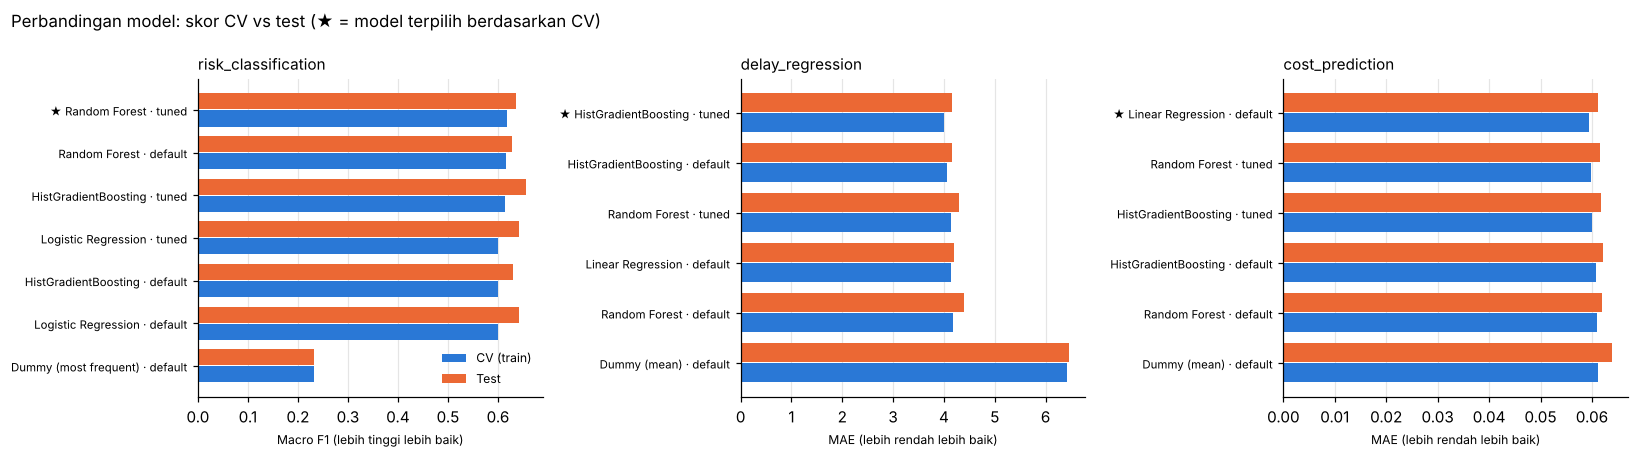

In [12]:
# Grafik perbandingan metrik utama (CV dan test) antar model
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, (task, res) in zip(axes, RESULTS.items()):
    ok = res[res.status == "OK"].copy()
    ok["label"] = ok.model.str.replace(" (sklearn)", "", regex=False) + " · " + ok.variant
    if task == "risk_classification":
        cvc, tsc, xl = "cv_f1_macro_mean", "test_f1_macro", "Macro F1 (lebih tinggi lebih baik)"
        ok = ok.sort_values(cvc)
    else:
        cvc, tsc, xl = "cv_MAE_mean", "test_MAE", "MAE (lebih rendah lebih baik)"
        ok = ok.sort_values(cvc, ascending=False)
    y = np.arange(len(ok))
    ax.barh(y - 0.2, ok[cvc], height=0.38, color=C_MAIN, label="CV (train)")
    ax.barh(y + 0.2, ok[tsc], height=0.38, color=C_ACCENT, label="Test")
    ax.set_yticks(y, [("★ " if b else "") + l for l, b in zip(ok.label, ok.is_best)], fontsize=7.5)
    ax.set_xlabel(xl, fontsize=8); ax.set_title(task, loc="left", fontsize=10); ax.grid(axis="y", visible=False)
axes[0].legend(frameon=False, fontsize=8, loc="lower right")
fig.suptitle("Perbandingan model: skor CV vs test (★ = model terpilih berdasarkan CV)", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); savefig(fig, "model_comparison.png"); plt.show()

## 10. Final evaluation (model terbaik per tugas)

### 10a. Risk Classification

Model terbaik: Random Forest (tuned)

              precision    recall  f1-score   support

         LOW      0.799     0.701     0.747       532
      MEDIUM      0.570     0.609     0.589       386
        HIGH      0.479     0.707     0.571        82

    accuracy                          0.666      1000
   macro avg      0.616     0.672     0.636      1000
weighted avg      0.684     0.666     0.671      1000

               prediksi LOW  prediksi MEDIUM  prediksi HIGH
aktual LOW              373              153              6
aktual MEDIUM            94              235             57
aktual HIGH               0               24             58


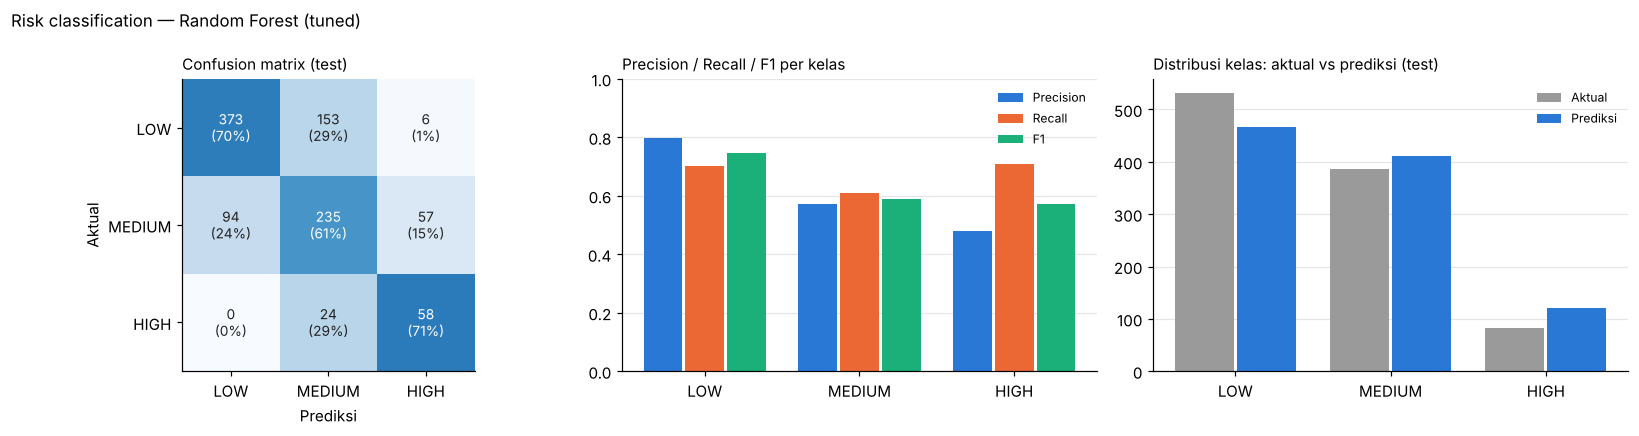

In [13]:
task = "risk_classification"; c = CTX[task]
best_cls = FITTED[task][BEST[task]]
yp = best_cls.predict(c["Xte"]).astype(int); yt = c["yte"]
print(f"Model terbaik: {BEST[task][0]} ({BEST[task][1]})\n")
print(classification_report(yt, yp, target_names=CLASSES, digits=3))
cm = confusion_matrix(yt, yp, labels=range(3))
display(pd.DataFrame(cm, index=[f"aktual {c_}" for c_ in CLASSES], columns=[f"prediksi {c_}" for c_ in CLASSES]))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
cmn = cm / cm.sum(axis=1, keepdims=True)
axes[0].imshow(cmn, cmap="Blues", vmin=0, vmax=1)
for i in range(3):
    for j in range(3):
        axes[0].text(j, i, f"{cm[i, j]}\n({cmn[i, j]:.0%})", ha="center", va="center", fontsize=9,
                     color="white" if cmn[i, j] > 0.55 else "#222")
axes[0].set_xticks(range(3), CLASSES); axes[0].set_yticks(range(3), CLASSES); axes[0].grid(False)
axes[0].set_xlabel("Prediksi"); axes[0].set_ylabel("Aktual"); axes[0].set_title("Confusion matrix (test)", loc="left", fontsize=10)

prf = pd.DataFrame({"Precision": precision_score(yt, yp, average=None, labels=range(3), zero_division=0),
                    "Recall": recall_score(yt, yp, average=None, labels=range(3), zero_division=0),
                    "F1": f1_score(yt, yp, average=None, labels=range(3), zero_division=0)}, index=CLASSES)
xx = np.arange(3)
for k, (col, colr) in enumerate(zip(prf.columns, C_CAT[:3])):
    axes[1].bar(xx + (k - 1) * 0.27, prf[col], width=0.25, color=colr, label=col)
axes[1].set_xticks(xx, CLASSES); axes[1].set_ylim(0, 1); axes[1].legend(frameon=False, fontsize=8)
axes[1].set_title("Precision / Recall / F1 per kelas", loc="left", fontsize=10); axes[1].grid(axis="x", visible=False)

dist = pd.DataFrame({"Aktual": pd.Series(yt).value_counts().reindex(range(3), fill_value=0).values,
                     "Prediksi": pd.Series(yp).value_counts().reindex(range(3), fill_value=0).values}, index=CLASSES)
axes[2].bar(xx - 0.2, dist["Aktual"], width=0.38, color=C_GRAY, label="Aktual")
axes[2].bar(xx + 0.2, dist["Prediksi"], width=0.38, color=C_MAIN, label="Prediksi")
axes[2].set_xticks(xx, CLASSES); axes[2].legend(frameon=False, fontsize=8)
axes[2].set_title("Distribusi kelas: aktual vs prediksi (test)", loc="left", fontsize=10); axes[2].grid(axis="x", visible=False)
fig.suptitle(f"Risk classification — {BEST[task][0]} ({BEST[task][1]})", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); savefig(fig, "risk_confusion_matrix_and_metrics.png"); plt.show()

### 10b. Delay Regression & 10c. Cost Prediction

delay_regression: MAE=4.1556 RMSE=5.4263 R2=0.5635 | residual mean=0.793
cost_prediction: MAE=0.0611 RMSE=0.0777 R2=0.0664 | residual mean=-0.153


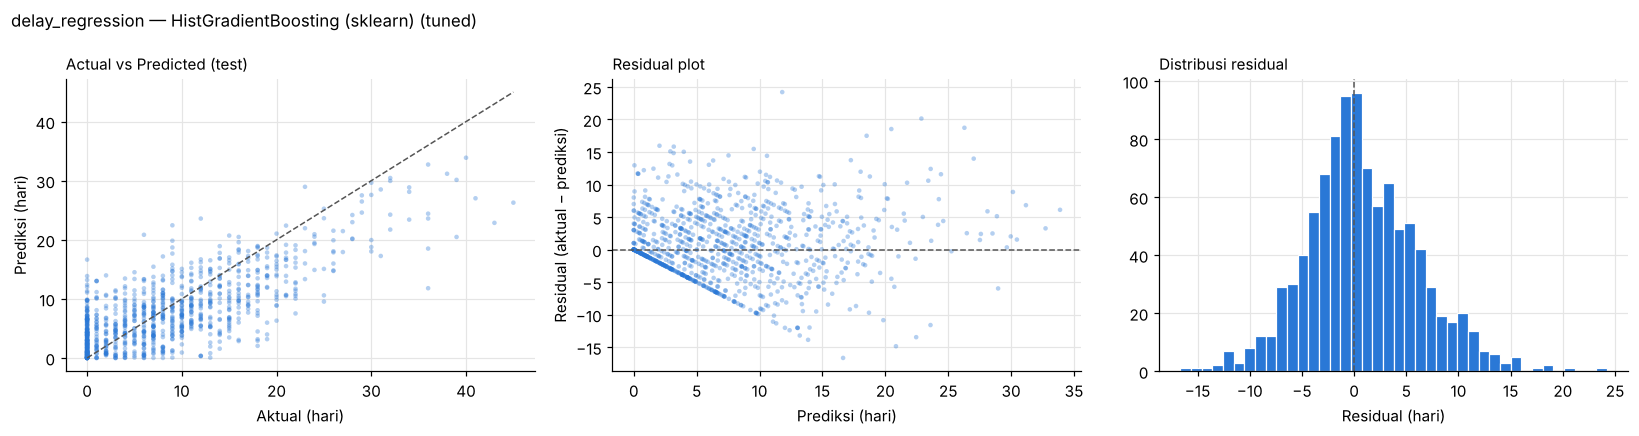

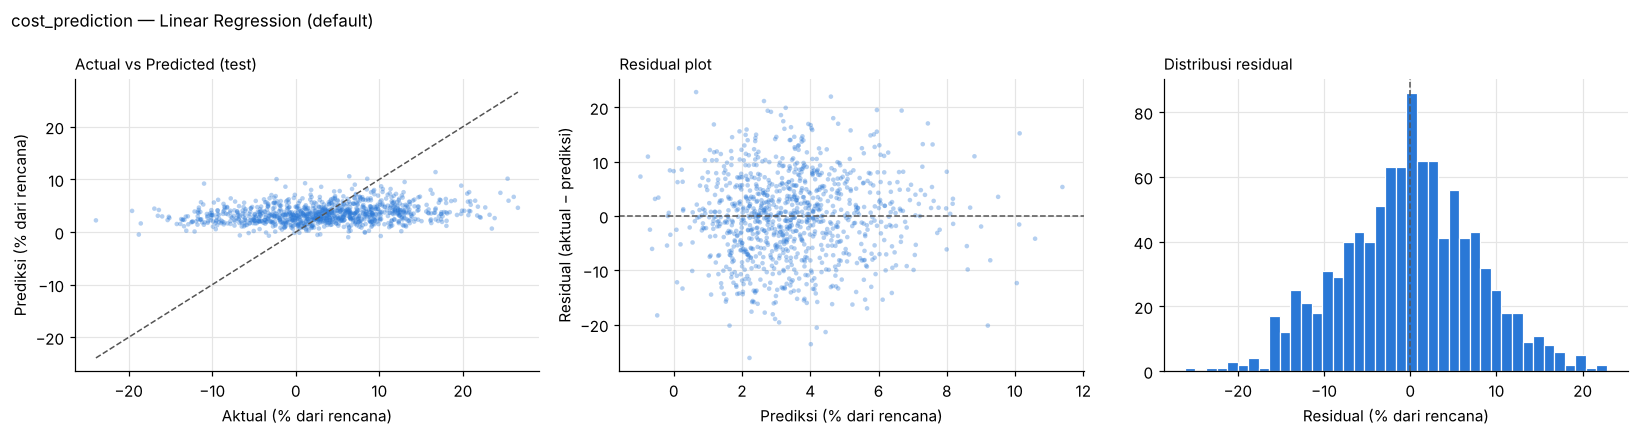

In [14]:
def regression_figures(task, unit, fname, scale=1.0, clip_min=None):
    c = CTX[task]; model = FITTED[task][BEST[task]]
    pred = model.predict(c["Xte"]) * 1.0
    if clip_min is not None: pred = np.clip(pred, clip_min, None)
    yt = c["yte"]; p, a = pred * scale, yt * scale; resid = a - p
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    axes[0].scatter(a, p, s=9, alpha=0.35, color=C_MAIN, edgecolor="none")
    lim = [min(a.min(), p.min()), max(a.max(), p.max())]
    axes[0].plot(lim, lim, color="#555", lw=1, ls="--"); axes[0].set_xlabel(f"Aktual ({unit})"); axes[0].set_ylabel(f"Prediksi ({unit})")
    axes[0].set_title("Actual vs Predicted (test)", loc="left", fontsize=10)
    axes[1].scatter(p, resid, s=9, alpha=0.35, color=C_MAIN, edgecolor="none"); axes[1].axhline(0, color="#555", lw=1, ls="--")
    axes[1].set_xlabel(f"Prediksi ({unit})"); axes[1].set_ylabel("Residual (aktual − prediksi)")
    axes[1].set_title("Residual plot", loc="left", fontsize=10)
    axes[2].hist(resid, bins=40, color=C_MAIN, edgecolor="white", linewidth=0.8); axes[2].axvline(0, color="#555", lw=1, ls="--")
    axes[2].set_xlabel(f"Residual ({unit})"); axes[2].set_title("Distribusi residual", loc="left", fontsize=10)
    fig.suptitle(f"{task} — {BEST[task][0]} ({BEST[task][1]})", x=0.01, ha="left", fontsize=11)
    plt.tight_layout(); savefig(fig, fname); plt.show()
    m = eval_regression(yt, pred)
    print(f"{task}: MAE={m['MAE']:.4f} RMSE={m['RMSE']:.4f} R2={m['R2']:.4f} | residual mean={resid.mean():.3f}")
    return pred

pred_delay = regression_figures("delay_regression", "hari", "delay_actual_vs_pred_residuals.png", clip_min=0.0)
pred_cost = regression_figures("cost_prediction", "% dari rencana", "cost_actual_vs_pred_residuals.png", scale=100)

### 10d. Ketidakpastian skor test (bootstrap 95% CI) & perbandingan dengan rujukan naif
Satu angka skor test bisa menyesatkan, jadi interval kepercayaan bootstrap dihitung dengan resampling baris test sebanyak 1.000 kali. Model dianggap *belajar sesuatu* hanya jika intervalnya **tidak tumpang tindih** dengan model Dummy.

In [15]:
rng = np.random.default_rng(SEED)
def bootstrap_ci(y, pred, fn, n=CONFIG["bootstrap_iterations"]):
    idx = rng.integers(0, len(y), (n, len(y)))
    vals = np.array([fn(y[i], pred[i]) for i in idx])
    return np.percentile(vals, [2.5, 97.5])

ci_rows = []
for task in RESULTS:
    c = CTX[task]; yt = c["yte"]
    is_clf = task == "risk_classification"
    fn = (lambda a, b: f1_score(a, b, average="macro", zero_division=0)) if is_clf else mean_absolute_error
    dummy_key = [k for k in FITTED[task] if k[0].startswith("Dummy")][0]
    for label, key in [("terbaik", BEST[task]), ("dummy", dummy_key)]:
        pr = FITTED[task][key].predict(c["Xte"])
        pr = pr.astype(int) if is_clf else (np.clip(pr, 0, None) if task == "delay_regression" else pr)
        lo, hi = bootstrap_ci(np.asarray(yt), np.asarray(pr), fn)
        ci_rows.append({"task": task, "model": f"{key[0]} ({key[1]})", "peran": label, "metrik": "Macro F1" if is_clf else "MAE",
                        "nilai_test": fn(np.asarray(yt), np.asarray(pr)), "ci95_low": lo, "ci95_high": hi})
ci = pd.DataFrame(ci_rows)
for task, g in ci.groupby("task", sort=False):
    b, d = g[g.peran == "terbaik"].iloc[0], g[g.peran == "dummy"].iloc[0]
    better = (b.ci95_low > d.ci95_high) if task == "risk_classification" else (b.ci95_high < d.ci95_low)
    ci.loc[g[g.peran == "terbaik"].index, "mengungguli_dummy_signifikan"] = better
display(ci.round(4))

                  task                                   model    peran    metrik  nilai_test  ci95_low  ci95_high mengungguli_dummy_signifikan
0  risk_classification                   Random Forest (tuned)  terbaik  Macro F1      0.6357    0.6011     0.6679                         True
1  risk_classification         Dummy (most frequent) (default)    dummy  Macro F1      0.2315    0.2228     0.2399                          NaN
2     delay_regression  HistGradientBoosting (sklearn) (tuned)  terbaik       MAE      4.1556    3.9332     4.3665                         True
3     delay_regression                  Dummy (mean) (default)    dummy       MAE      6.4583    6.1493     6.7554                          NaN
4      cost_prediction             Linear Regression (default)  terbaik       MAE      0.0611    0.0580     0.0640                        False
5      cost_prediction                  Dummy (mean) (default)    dummy       MAE      0.0638    0.0608     0.0668                      

### 10e. Validasi berdasarkan sumber data
- **Empiris vs sintetis:** seluruh baris training dan test adalah **sintetis** dari satu sumber. Evaluasi terpisah untuk data empiris **tidak dapat dilakukan** karena jumlahnya 0. Survei Aceh adalah data persepsi tanpa outcome, sehingga tidak bisa dipakai menguji model.
- **Lintas sumber:** satu-satunya sumber lain di dataset final (CONSTRUCTION_DELAY_PRED_ALG) memiliki target berbeda (`delay_risk_binary`) dan fitur yang hampir tidak beririsan. Fitur bersama hanya `flag_kendala_material`, `flag_kendala_keselamatan`, `jumlah_pekerja`, `jumlah_insiden_keselamatan`, dan `progress_persen`, dengan definisi flag yang berbeda pula (kejadian vs kondisi). Sesuai brief, evaluasi lintas sumber **tidak dipaksakan**.

In [16]:
src_rows = []
for task in RESULTS:
    c = CTX[task]; df = data[task].iloc[SPLIT[task]["test"]]
    pr = FITTED[task][BEST[task]].predict(c["Xte"])
    for (src, syn), idx in df.groupby(["meta_source_dataset", "meta_is_synthetic"]).indices.items():
        yt_, pr_ = np.asarray(c["yte"])[idx], np.asarray(pr)[idx]
        m = eval_classification(yt_, pr_.astype(int)) if task == "risk_classification" else eval_regression(yt_, np.clip(pr_, 0, None) if task == "delay_regression" else pr_)
        src_rows.append({"task": task, "source_dataset": src, "is_synthetic": syn, "n_test": len(idx),
                         "metrik_utama": m["f1_macro"] if task == "risk_classification" else m["MAE"]})
src_eval = pd.DataFrame(src_rows)
src_eval["catatan"] = "satu-satunya sumber; data empiris = 0 baris -> evaluasi empiris tidak dapat dilakukan"
display(src_eval.round(4))

                  task              source_dataset  is_synthetic  n_test  metrik_utama                                                                                catatan
0  risk_classification  CONSTRUCTION_DELAY_RISK_GH          True    1000        0.6357  satu-satunya sumber; data empiris = 0 baris -> evaluasi empiris tidak dapat dilakukan
1     delay_regression  CONSTRUCTION_DELAY_RISK_GH          True    1000        4.1556  satu-satunya sumber; data empiris = 0 baris -> evaluasi empiris tidak dapat dilakukan
2      cost_prediction  CONSTRUCTION_DELAY_RISK_GH          True    1000        0.0611  satu-satunya sumber; data empiris = 0 baris -> evaluasi empiris tidak dapat dilakukan


## 10f. Eksperimen kompatibilitas Way2Home (fitur terbatas)

Service Way2Home saat ini **tidak** mengirim anggaran, jumlah pekerja, utilisasi alat, durasi, atau jumlah insiden. Fitur yang punya padanan di input service hanya:
- `flag_kendala_*` (dari `kategori`);
- `dampak_waktu_*` (dari `dampak_waktu_hari`);
- `progress_persen`.

Algoritma dan hyperparameter terbaik masing-masing tugas dilatih ulang **hanya dengan fitur ini**, memakai split yang sama. Tujuannya mengukur seberapa besar performa turun jika model dipakai dengan input aplikasi yang tersedia sekarang.

In [17]:
W2H_COMPAT = ["flag_kendala_material", "flag_kendala_cuaca", "flag_kendala_keselamatan",
              "dampak_waktu_hari", "dampak_waktu_material_hari", "dampak_waktu_cuaca_hari", "progress_persen"]
COMPAT_FITTED, compat_rows = {}, []
for task in RESULTS:
    c = CTX[task]; feats = [f for f in W2H_COMPAT if f in FEATURES[task]]
    full = FITTED[task][BEST[task]]
    is_clf = task == "risk_classification"
    model = Pipeline([("prep", make_preprocessor(c["Xtr"][feats], scale=isinstance(full.named_steps["model"], (LogisticRegression, LinearRegression)))),
                      ("model", clone(full.named_steps["model"]))])
    fit_params = {"model__sample_weight": compute_sample_weight("balanced", c["ytr"])} if BEST[task][0] == "XGBoost" and is_clf else {}
    cvs = cross_val_score(model, c["Xtr"][feats], c["ytr"], groups=c["gtr"], cv=c["cv"], scoring=c["scoring"], params=fit_params, n_jobs=CONFIG["n_jobs"])
    model.fit(c["Xtr"][feats], c["ytr"], **fit_params)
    pr = model.predict(c["Xte"][feats])
    if is_clf:
        m_c = eval_classification(c["yte"], pr.astype(int)); full_m = RESULTS[task].query("is_best").iloc[0]["test_f1_macro"]
        compat_rows.append({"task": task, "model": f"{BEST[task][0]} ({BEST[task][1]})", "metrik": "Macro F1",
                            "full_features_test": full_m, "w2h_compatible_cv": cvs.mean(), "w2h_compatible_test": m_c["f1_macro"]})
    else:
        if task == "delay_regression": pr = np.clip(pr, 0, None)
        m_c = eval_regression(c["yte"], pr); full_m = RESULTS[task].query("is_best").iloc[0]["test_MAE"]
        compat_rows.append({"task": task, "model": f"{BEST[task][0]} ({BEST[task][1]})", "metrik": "MAE",
                            "full_features_test": full_m, "w2h_compatible_cv": -cvs.mean(), "w2h_compatible_test": m_c["MAE"]})
    COMPAT_FITTED[task] = (model, feats, m_c, cvs)
compat = pd.DataFrame(compat_rows)
display(compat.round(4))

                  task                                   model    metrik  full_features_test  w2h_compatible_cv  w2h_compatible_test
0  risk_classification                   Random Forest (tuned)  Macro F1              0.6357             0.5209               0.5388
1     delay_regression  HistGradientBoosting (sklearn) (tuned)       MAE              4.1556             4.8854               5.0793
2      cost_prediction             Linear Regression (default)       MAE              0.0611             0.0600               0.0621


## 11. Explainable AI

**Metode utama: SHAP** (`TreeExplainer` untuk model pohon, `LinearExplainer` untuk model linear). SHAP hanya dipakai jika library `shap` terpasang.

**Metode pendamping yang selalu dijalankan (model-agnostic, scikit-learn):**
- **Permutation importance** pada data test: penurunan metrik utama saat satu fitur diacak.
- **Arah pengaruh** dari *partial dependence*: perubahan rata-rata prediksi (untuk klasifikasi, peluang kelas HIGH) saat fitur bergerak dari persentil 5 ke persentil 95.

> Interpretasi bersifat **asosiatif**: menunjukkan fitur yang dipakai model untuk memprediksi, **bukan** sebab-akibat. Data sintetis membuat pola ini mencerminkan cara data dibangkitkan, belum tentu kondisi lapangan.

In [18]:
FI_ROWS, DIRECTION = [], {}
def pd_direction(model, X, feat, is_clf):
    # Arah = rata-rata prediksi di P95 − di P5 (klasifikasi: peluang HIGH)
    lo, hi = np.nanpercentile(X[feat].astype(float), [5, 95])
    if lo == hi:
        return 0.0
    # sklearn menolak kolom integer untuk partial dependence -> konversi ke float (nilai tidak berubah)
    r = partial_dependence(model, X.astype(float), [feat], grid_resolution=20, percentiles=(0.05, 0.95),
                           response_method="predict_proba" if is_clf else "auto", kind="average")
    avg = r["average"]
    curve = avg[CLS2INT["HIGH"]] if is_clf and avg.shape[0] == 3 else avg[0]
    return float(curve[-1] - curve[0])

for task in RESULTS:
    c = CTX[task]; model = FITTED[task][BEST[task]]; is_clf = task == "risk_classification"
    scoring = "f1_macro" if is_clf else "neg_mean_absolute_error"
    for variant, mdl, feats in [("full", model, FEATURES[task]), ("w2h_compatible", COMPAT_FITTED[task][0], COMPAT_FITTED[task][1])]:
        pi = permutation_importance(mdl, c["Xte"][feats], c["yte"], scoring=scoring, n_repeats=CONFIG["permutation_repeats"],
                                    random_state=SEED, n_jobs=CONFIG["n_jobs"])
        for f, m_, s_ in zip(feats, pi.importances_mean, pi.importances_std):
            d = pd_direction(mdl, c["Xte"][feats], f, is_clf)
            FI_ROWS.append({"task": task, "variant": variant, "model": f"{BEST[task][0]} ({BEST[task][1]})",
                            "method": "permutation_importance(test)", "feature": f, "importance": m_, "importance_std": s_,
                            "pd_effect_p5_to_p95": d, "direction": "meningkatkan" if d > 1e-9 else ("menurunkan" if d < -1e-9 else "datar")})
        est = mdl.named_steps["model"]
        if hasattr(est, "feature_importances_"):
            names = mdl.named_steps["prep"].get_feature_names_out()
            for f, v in zip(names, est.feature_importances_):
                FI_ROWS.append({"task": task, "variant": variant, "model": f"{BEST[task][0]} ({BEST[task][1]})",
                                "method": "native_feature_importance", "feature": f, "importance": v})
FI = pd.DataFrame(FI_ROWS)
for task in RESULTS:
    t = FI[(FI.task == task) & (FI.variant == "full") & (FI.method == "permutation_importance(test)")].sort_values("importance", ascending=False)
    print(f"\n=== {task}"); display(t[["feature", "importance", "importance_std", "pd_effect_p5_to_p95", "direction"]].round(4))


=== risk_classification
                       feature  importance  importance_std  pd_effect_p5_to_p95     direction
3            dampak_waktu_hari      0.1503          0.0131               0.3283  meningkatkan
7           durasi_proyek_hari      0.0709          0.0152               0.1824  meningkatkan
11  jumlah_insiden_keselamatan      0.0656          0.0090               0.2963  meningkatkan
8              progress_persen      0.0171          0.0060              -0.0954    menurunkan
10  utilisasi_peralatan_persen      0.0109          0.0052              -0.0457    menurunkan
9               jumlah_pekerja      0.0042          0.0038               0.0015  meningkatkan
5      dampak_waktu_cuaca_hari      0.0007          0.0015               0.0075  meningkatkan
1           flag_kendala_cuaca      0.0000          0.0000              -0.0005    menurunkan
0        flag_kendala_material     -0.0001          0.0006               0.0000  meningkatkan
2     flag_kendala_keselamatan     

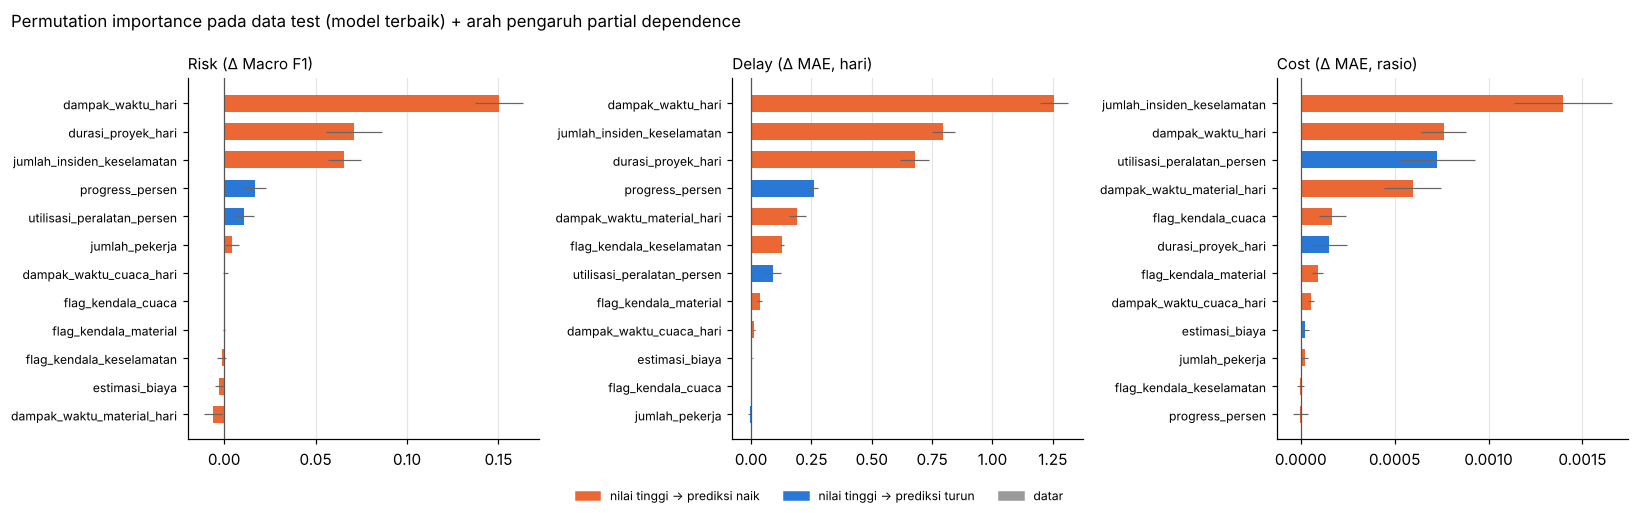

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
titles = {"risk_classification": "Risk (Δ Macro F1)", "delay_regression": "Delay (Δ MAE, hari)", "cost_prediction": "Cost (Δ MAE, rasio)"}
for ax, task in zip(axes, RESULTS):
    t = FI[(FI.task == task) & (FI.variant == "full") & (FI.method == "permutation_importance(test)")].sort_values("importance")
    colors = [C_ACCENT if d == "meningkatkan" else (C_MAIN if d == "menurunkan" else C_GRAY) for d in t.direction]
    ax.barh(t.feature, t.importance, xerr=t.importance_std, color=colors, height=0.6, error_kw={"elinewidth": 0.8, "ecolor": "#666"})
    ax.set_title(titles[task], loc="left", fontsize=10); ax.tick_params(axis="y", labelsize=8); ax.grid(axis="y", visible=False)
    ax.axvline(0, color="#555", lw=0.8)
from matplotlib.patches import Patch
fig.legend(handles=[Patch(color=C_ACCENT, label="nilai tinggi → prediksi naik"), Patch(color=C_MAIN, label="nilai tinggi → prediksi turun"),
                    Patch(color=C_GRAY, label="datar")], loc="lower center", ncol=3, frameon=False, fontsize=8, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Permutation importance pada data test (model terbaik) + arah pengaruh partial dependence", x=0.01, ha="left", fontsize=11)
plt.tight_layout(); savefig(fig, "feature_importance_permutation.png"); plt.show()

In [20]:
# ---------- SHAP (jika tersedia) ----------
SHAP_STATUS = {}
def shap_values_for(task, model, Xbg, Xexp):
    prep, est = model.named_steps["prep"], model.named_steps["model"]
    names = list(prep.get_feature_names_out())
    A_bg, A = prep.transform(Xbg), prep.transform(Xexp)
    if isinstance(est, (LogisticRegression, LinearRegression)):
        explainer = shap.LinearExplainer(est, A_bg)
        sv = explainer.shap_values(A)
    else:
        try:
            explainer = shap.TreeExplainer(est)
            sv = explainer.shap_values(A)
        except Exception:
            f = est.predict_proba if task == "risk_classification" else est.predict
            explainer = shap.Explainer(f, shap.maskers.Independent(A_bg[:200]), algorithm="permutation")
            sv = explainer(A).values
    sv = np.asarray(sv) if not isinstance(sv, list) else np.stack(sv, axis=-1)
    if sv.ndim == 3:                       # (n, fitur, kelas) atau (kelas, n, fitur)
        if sv.shape[0] == 3 and sv.shape[1] == A.shape[0]:
            sv = np.moveaxis(sv, 0, -1)
        sv = sv[:, :, CLS2INT["HIGH"]]       # jelaskan kelas HIGH
    return sv, pd.DataFrame(A, columns=names)

if HAS_SHAP:
    for task in RESULTS:
        try:
            c = CTX[task]; model = FITTED[task][BEST[task]]
            Xexp = c["Xte"].sample(min(500, len(c["Xte"])), random_state=SEED)
            sv, Adf = shap_values_for(task, model, c["Xtr"].sample(min(500, len(c["Xtr"])), random_state=SEED), Xexp)
            plt.figure()
            shap.summary_plot(sv, Adf, show=False, plot_size=(8, 4.5))
            plt.title(f"SHAP summary — {task}" + (" (kelas HIGH)" if task == "risk_classification" else ""), loc="left", fontsize=10)
            plt.savefig(FIG / f"shap_summary_{task}.png", bbox_inches="tight", dpi=150); plt.show()
            for j, f in enumerate(Adf.columns):
                corr = np.corrcoef(Adf[f], sv[:, j])[0, 1] if Adf[f].std() > 0 else 0.0
                FI_ROWS.append({"task": task, "variant": "full", "model": f"{BEST[task][0]} ({BEST[task][1]})", "method": "mean_abs_shap",
                                "feature": f, "importance": float(np.abs(sv[:, j]).mean()),
                                "direction": "meningkatkan" if corr > 0.05 else ("menurunkan" if corr < -0.05 else "campuran/datar")})
            SHAP_STATUS[task] = "OK"
        except Exception as e:
            SHAP_STATUS[task] = f"GAGAL: {type(e).__name__}: {e}"
    FI = pd.DataFrame(FI_ROWS)
else:
    SHAP_STATUS = {t: f"SKIPPED: library shap {SHAP_VER}; dipakai permutation importance + partial dependence" for t in RESULTS}
print(json.dumps(SHAP_STATUS, indent=1, ensure_ascii=False))

{
 "risk_classification": "SKIPPED: library shap NOT INSTALLED; dipakai permutation importance + partial dependence",
 "delay_regression": "SKIPPED: library shap NOT INSTALLED; dipakai permutation importance + partial dependence",
 "cost_prediction": "SKIPPED: library shap NOT INSTALLED; dipakai permutation importance + partial dependence"
}


In [21]:
# Ringkasan faktor (asosiatif) per tugas — diambil dari permutation importance + arah partial dependence (atau SHAP jika ada)
def top_factors(task, direction, k=4):
    method = "mean_abs_shap" if SHAP_STATUS.get(task) == "OK" else "permutation_importance(test)"
    t = FI[(FI.task == task) & (FI.variant == "full") & (FI.method == method) & (FI.importance > 0)]
    return t[t.direction == direction].sort_values("importance", ascending=False).feature.head(k).tolist()

FACTORS = {
  "risk_meningkatkan_HIGH": top_factors("risk_classification", "meningkatkan"),
  "risk_menurunkan_HIGH": top_factors("risk_classification", "menurunkan"),
  "delay_berasosiasi_naik": top_factors("delay_regression", "meningkatkan"),
  "delay_berasosiasi_turun": top_factors("delay_regression", "menurunkan"),
  "cost_berasosiasi_naik": top_factors("cost_prediction", "meningkatkan"),
  "cost_berasosiasi_turun": top_factors("cost_prediction", "menurunkan"),
}
for k, v in FACTORS.items():
    print(f"{k:26s}: {v}")

risk_meningkatkan_HIGH    : ['dampak_waktu_hari', 'durasi_proyek_hari', 'jumlah_insiden_keselamatan', 'jumlah_pekerja']
risk_menurunkan_HIGH      : ['progress_persen', 'utilisasi_peralatan_persen']
delay_berasosiasi_naik    : ['dampak_waktu_hari', 'jumlah_insiden_keselamatan', 'durasi_proyek_hari', 'dampak_waktu_material_hari']
delay_berasosiasi_turun   : ['progress_persen', 'utilisasi_peralatan_persen']
cost_berasosiasi_naik     : ['jumlah_insiden_keselamatan', 'dampak_waktu_hari', 'dampak_waktu_material_hari', 'flag_kendala_cuaca']
cost_berasosiasi_turun    : ['utilisasi_peralatan_persen', 'durasi_proyek_hari', 'estimasi_biaya']


## 12. Model selection

Model terpilih per tugas mengikuti skor CV metrik utama (bagian 9). Untuk setiap tugas diekspor dua varian:

- **`*_model.joblib`** (full features): model terbaik dengan 12 fitur. Dipakai untuk riset/skripsi atau jika aplikasi kelak mengirim konteks proyek.
- **`*_model_w2h_compatible.joblib`**: algoritma dan hyperparameter yang sama, hanya dengan fitur yang tersedia di input service saat ini. Ini default di modul inference `src/w2h_ml.py`.

Model biaya diberi status **`deployable=false`** jika tidak mengungguli Dummy secara signifikan (bootstrap CI pada 10d).

Model yang diekspor adalah model yang di-fit pada **data training saja**, sehingga metrik test di metadata benar-benar berlaku untuk objek yang tersimpan.

In [22]:
SELECTED = {}
for task in RESULTS:
    row = RESULTS[task].query("is_best").iloc[0]
    sig = bool(ci[(ci.task == task) & (ci.peran == "terbaik")].mengungguli_dummy_signifikan.iloc[0])
    SELECTED[task] = {"algorithm": row.model, "variant": row.variant, "beats_dummy_significantly": sig,
                      "deployable": sig, "reason": "unggul signifikan atas Dummy" if sig else "TIDAK unggul signifikan atas Dummy pada data test"}
display(pd.DataFrame(SELECTED).T)

                                          algorithm  variant beats_dummy_significantly deployable                                             reason
risk_classification                   Random Forest    tuned                      True       True                       unggul signifikan atas Dummy
delay_regression     HistGradientBoosting (sklearn)    tuned                      True       True                       unggul signifikan atas Dummy
cost_prediction                   Linear Regression  default                     False      False  TIDAK unggul signifikan atas Dummy pada data test


## 13. Model export (model + pipeline preprocessing dalam satu objek, metadata, laporan)

In [23]:
def feature_dtypes(X):
    return {c: str(X[c].dtype) for c in X.columns}

def train_composition(task):
    d = data[task].iloc[SPLIT[task]["train"]]
    return {"n_train": int(len(d)), "n_test": int(len(SPLIT[task]["test"])),
            "by_source": d.meta_source_dataset.value_counts().to_dict(),
            "synthetic": int(d.meta_is_synthetic.sum()), "empirical": int((~d.meta_is_synthetic.astype(bool)).sum())}

ALL_META = {}
for task in RESULTS:
    c = CTX[task]; row = RESULTS[task].query("is_best").iloc[0]
    is_clf = task == "risk_classification"
    best = FITTED[task][BEST[task]]
    compat_model, compat_feats, compat_m, compat_cv = COMPAT_FITTED[task]
    for variant, obj, feats, metrics in [
        ("full", best, FEATURES[task], {k.replace("test_", ""): row[k] for k in row.index if k.startswith("test_")}),
        ("w2h_compatible", compat_model, compat_feats, compat_m)]:
        export_obj = ClippedRegressor.from_fitted(obj, min_value=0.0) if task == "delay_regression" else obj
        stem = f"{task}_model" + ("" if variant == "full" else "_w2h_compatible")
        joblib.dump(export_obj, MODELS / f"{stem}.joblib", compress=3)
        meta = {
            "model_name": stem, "model_version": "1.0.0", "created_at": pd.Timestamp.now(tz="Asia/Jakarta").isoformat(),
            "task": task, "problem_type": "multiclass_classification" if is_clf else "regression",
            "target": TASK_TARGET[task], "class_order": CLASSES if is_clf else None,
            "algorithm": row.model, "hyperparameter_variant": row.variant, "variant": variant,
            "best_params": json.loads(row.best_params), "features": feats, "feature_order": feats,
            "feature_dtypes": feature_dtypes(c["Xtr"][feats]),
            "primary_metric": CONFIG["primary_metric"][task],
            "cv_score_primary": float(row["cv_f1_macro_mean" if is_clf else "cv_MAE_mean"]) if variant == "full" else float(abs(compat_cv.mean())),
            "test_metrics": {k: (float(v) if isinstance(v, (int, float, np.floating)) else v) for k, v in metrics.items()},
            "beats_dummy_significantly": SELECTED[task]["beats_dummy_significantly"] if variant == "full" else None,
            "deployable": SELECTED[task]["deployable"],
            "postprocessing": "prediksi di-clip >= 0 (ClippedRegressor)" if task == "delay_regression" else None,
            "training_data": {"file": f"data/final/{TASK_FILES[task]}", **train_composition(task)},
            "split": {"method": "StratifiedGroupKFold fold-1 sebagai test (80/20), group=meta_project_group_id",
                      "cv": "StratifiedGroupKFold(5)" if is_clf else "GroupKFold(5, shuffle)", "random_state": SEED},
            "library_versions": VERSIONS, "requires_import": "src/w2h_ml.py (ClippedRegressor)" if task == "delay_regression" else None,
            "limitations": ["Data training 100% sintetis (tanpa dokumentasi asal) — performa belum tervalidasi pada proyek nyata.",
                            "Unit training = agregat proyek; input Way2Home = satu kendala (granularitas berbeda).",
                            "Interpretasi fitur bersifat asosiatif, bukan sebab-akibat."],
        }
        (MODELS / f"{stem}_metadata.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
        ALL_META[stem] = meta

# Hasil evaluasi per tugas
RESULTS["risk_classification"].to_csv(REPORTS / "risk_classification_results.csv", index=False)
RESULTS["delay_regression"].to_csv(REPORTS / "delay_regression_results.csv", index=False)
RESULTS["cost_prediction"].to_csv(REPORTS / "cost_prediction_results.csv", index=False)
cmp_rows = []
for task, res in RESULTS.items():
    for _, r in res.iterrows():
        cmp_rows.append({"task": task, "model": r.model, "variant": r.variant, "role": r.role, "status": r.status,
                         "primary_metric": CONFIG["primary_metric"][task],
                         "cv_primary": r.get("cv_f1_macro_mean" if task == "risk_classification" else "cv_MAE_mean"),
                         "test_primary": r.get("test_f1_macro" if task == "risk_classification" else "test_MAE"),
                         "test_secondary": r.get("test_f1_weighted" if task == "risk_classification" else "test_R2"),
                         "secondary_metric": "f1_weighted" if task == "risk_classification" else "R2",
                         "is_best": bool(r.get("is_best", False)), "note": r.get("note", "")})
pd.DataFrame(cmp_rows).to_csv(REPORTS / "model_comparison.csv", index=False)
FI.to_csv(REPORTS / "feature_importance.csv", index=False)
ci.to_csv(REPORTS / "bootstrap_ci_test.csv", index=False)
compat.to_csv(REPORTS / "w2h_compatible_comparison.csv", index=False)
src_eval.to_csv(REPORTS / "source_based_evaluation.csv", index=False)

# Simpan juga semua kandidat (default & tuned) untuk reprodusibilitas
for task, models in FITTED.items():
    for (name, var), m in models.items():
        fn = f"{task}__{name.split(' (')[0].replace(' ', '_').lower()}__{var}.joblib"
        joblib.dump(m, MODELS / "candidates" / fn, compress=3)

# model_metadata.json di root project: ringkasan seluruh model
root_meta = {"project": "Way2Home — AI Analisis Kendala", "config": CONFIG, "library_versions": VERSIONS,
             "shap_status": SHAP_STATUS, "selected": SELECTED, "factors_associative": FACTORS, "models": ALL_META}
(ROOT / "model_metadata.json").write_text(json.dumps(root_meta, indent=2, ensure_ascii=False, default=str), encoding="utf-8")

for p in sorted(MODELS.glob("*.joblib")) + sorted(REPORTS.glob("*.csv")) + sorted(FIG.glob("*.png")):
    print(f"{str(p.relative_to(ROOT)):58s} {p.stat().st_size / 1024:9.1f} KB")
print("candidates:", len(list((MODELS / 'candidates').glob('*.joblib'))), "file")

models/cost_prediction_model.joblib                              2.1 KB
models/cost_prediction_model_w2h_compatible.joblib               1.8 KB
models/delay_regression_model.joblib                            90.5 KB
models/delay_regression_model_w2h_compatible.joblib             66.7 KB
models/risk_classification_model.joblib                       1667.7 KB
models/risk_classification_model_w2h_compatible.joblib        1624.8 KB
reports/00_dataset_audit_table.csv                               1.8 KB
reports/00_target_signal_check.csv                               0.3 KB
reports/00_way2home_input_mapping.csv                            0.8 KB
reports/bootstrap_ci_test.csv                                    0.8 KB
reports/cost_prediction_results.csv                              1.7 KB
reports/delay_regression_results.csv                             1.6 KB
reports/feature_importance.csv                                  12.4 KB
reports/final_model_summary.csv                                 

### Uji muat ulang & contoh inference
Model dimuat ulang dari disk dan dicoba pada contoh input berformat `ai-kendala.service.ts`. Hasilnya **hanya** mengisi field yang punya dasar model. Field `summary`, `checklist_factors`, dan `recommended_options` sengaja dibiarkan `None`, karena memerlukan basis pengetahuan dan data penyelesaian kendala.

In [24]:
# 1) Konsistensi: model yang dimuat ulang memberi prediksi identik dengan model di memori
for task in RESULTS:
    loaded = joblib.load(MODELS / f"{task}_model.joblib")
    a = loaded.predict(CTX[task]["Xte"]); b = FITTED[task][BEST[task]].predict(CTX[task]["Xte"])
    if task == "delay_regression": b = np.clip(b, 0, None)
    assert np.allclose(a, b), task
print("Reload check: OK (prediksi identik)")

# 2) Contoh payload service (nilai ilustratif, bukan data nyata)
payload = {"kategori": "MATERIAL", "deskripsi": "Pengiriman bata ringan terlambat", "kondisi_pekerjaan": "TERHAMBAT_SEBAGIAN",
           "dampak_waktu_hari": 6, "informasi_tambahan": None, "nama_tahap": "Struktur", "judul_subtask": "Pasang dinding lantai 1",
           "bobot_subtask": 8, "nama_desain": "Tipe 45", "status_proyek": "BERJALAN"}
feats = way2home_input_to_features(payload)
print("Fitur turunan dari payload:", feats)
predictor = Way2HomeKendalaPredictor(MODELS, variant="w2h_compatible")
out = predictor.predict(feats)
print(json.dumps(out, indent=1, ensure_ascii=False, default=str))

Reload check: OK (prediksi identik)
Fitur turunan dari payload: {'flag_kendala_material': 1, 'flag_kendala_cuaca': 0, 'flag_kendala_keselamatan': 0, 'flag_kendala_peralatan': 0, 'dampak_waktu_hari': 6.0, 'dampak_waktu_material_hari': 6.0, 'dampak_waktu_cuaca_hari': 0.0, 'progress_persen': nan}
{
 "variant": "w2h_compatible",
 "model_outputs": {
  "risk_level": "LOW",
  "risk_proba": {
   "LOW": 0.496,
   "MEDIUM": 0.3564,
   "HIGH": 0.1476
  },
  "delay_days": 4.4,
  "cost_overrun_ratio": 0.0281,
  "cost_model_deployable": false
 },
 "missing_features": {
  "risk_classification": [
   "progress_persen"
  ],
  "delay_regression": [
   "progress_persen"
  ],
  "cost_prediction": [
   "progress_persen"
  ]
 },
 "way2home_fields": {
  "risk_level": "LOW",
  "summary": null,
  "metrics": {
   "delay_estimate_days": 4.4,
   "overbudget_risk": null,
   "cost_notes": "Model biaya belum layak dipakai (tidak mengungguli baseline pada data uji)."
  },
  "checklist_factors": null,
  "recommended_o

## 14. Kesimpulan & rekomendasi

In [25]:
summary_rows = []
for task in RESULTS:
    r = RESULTS[task].query("is_best").iloc[0]; d = ci[(ci.task == task) & (ci.peran == "dummy")].iloc[0]
    b = ci[(ci.task == task) & (ci.peran == "terbaik")].iloc[0]; cp = compat[compat.task == task].iloc[0]
    summary_rows.append({"tugas": task, "model_terpilih": f"{r.model} ({r.variant})", "metrik": b.metrik,
                         "test_terbaik": round(b.nilai_test, 3), "CI95": f"{b.ci95_low:.3f}–{b.ci95_high:.3f}",
                         "test_dummy": round(d.nilai_test, 3), "w2h_compatible_test": round(cp.w2h_compatible_test, 3),
                         "deployable": SELECTED[task]["deployable"]})
final_summary = pd.DataFrame(summary_rows)
display(final_summary)
final_summary.to_csv(REPORTS / "final_model_summary.csv", index=False)

                 tugas                          model_terpilih    metrik  test_terbaik         CI95  test_dummy  w2h_compatible_test  deployable
0  risk_classification                   Random Forest (tuned)  Macro F1         0.636  0.601–0.668       0.232                0.539        True
1     delay_regression  HistGradientBoosting (sklearn) (tuned)       MAE         4.156  3.933–4.367       6.458                5.079        True
2      cost_prediction             Linear Regression (default)       MAE         0.061  0.058–0.064       0.064                0.062       False


**Interpretasi.** Angka di bawah berasal dari eksekusi pada lingkungan **tanpa XGBoost/CatBoost**. Jika notebook dijalankan ulang dengan kedua library tersebut, tabel di atas yang menjadi acuan.

1. **Risk classification: Random Forest (tuned)**, Macro F1 test **0,636** (CI95 0,601–0,668) vs Dummy 0,232.
   - Recall HIGH **0,71** dengan precision **0,48**: sebagian besar proyek HIGH tertangkap, tetapi lebih dari separuh peringatan HIGH adalah *false alarm*. Ini wajar untuk sistem pendukung yang ditinjau Pengawas, tapi tidak untuk keputusan otomatis.
   - Tidak ada proyek HIGH yang diprediksi LOW. Kesalahan terjadi di kelas yang bersebelahan (MEDIUM).
   - HistGradientBoosting (tuned) mencetak Macro F1 test sedikit lebih tinggi (0,656). Selisihnya masih **di dalam interval ketidakpastian**, dan pemilihan model tetap memakai skor CV agar test set tidak dipakai untuk memilih.
   - Accuracy (0,67) tidak dijadikan dasar, karena menebak "LOW" untuk semua proyek sudah mencapai 0,53.
2. **Delay regression: HistGradientBoosting (tuned)**, MAE test **4,16 hari** (CI95 3,93–4,37) vs Dummy 6,46 hari, R² 0,56.
   - Residual positif membesar pada keterlambatan > 20 hari: model cenderung *underpredict* keterlambatan ekstrem.
   - Pita diagonal pada residual plot berasal dari proyek dengan keterlambatan aktual 0 hari, yang tetap diprediksi > 0.
   - Linear Regression (MAE 4,20) hampir setara. Hubungan dalam data ini sebagian besar linear.
3. **Cost prediction: Linear Regression**, MAE 0,061 vs Dummy 0,064, R² 0,07.
   - Interval kepercayaan **tumpang tindih** dengan Dummy, sehingga model **tidak** dinyatakan belajar sinyal yang berarti. Model diekspor dengan `deployable=false`.
   - `metrics.overbudget_risk` dan `cost_notes` tetap memakai logika service yang ada. Ini *negative result* yang sah untuk dilaporkan.
4. **Kompatibilitas Way2Home.** Hanya dengan fitur yang tersedia di service, Macro F1 risk turun menjadi **0,54** dan MAE delay naik menjadi **5,08 hari**. Keduanya masih lebih baik daripada Dummy. Konteks proyek (durasi, insiden keselamatan, utilisasi alat) ikut menyumbang prediksi.
5. **Explainability** (permutation importance + partial dependence; SHAP belum tersedia di lingkungan ini).
   - Prediksi risiko HIGH dan keterlambatan **berasosiasi** dengan `dampak_waktu_hari` yang lebih besar, `jumlah_insiden_keselamatan` yang lebih banyak, dan `durasi_proyek_hari` yang lebih panjang.
   - Prediksi lebih rendah berasosiasi dengan `progress_persen` dan `utilisasi_peralatan_persen` yang lebih tinggi.
   - Flag kategori (material/cuaca) hampir tidak berkontribusi setelah jumlah hari dampaknya diketahui.
   - Semua ini **asosiasi dalam data sintetis**, bukan bukti sebab-akibat.

**Rekomendasi:**
- Gunakan model risk dan delay hanya sebagai **dasar analisis pendukung** yang ditinjau Pengawas, bukan keputusan otomatis.
- Prioritas data: kumpulkan riwayat kendala Way2Home (Supabase) beserta outcome aktual (hari keterlambatan, biaya realisasi) untuk retraining dan validasi **empiris**. Tanpa itu, performa di atas tidak boleh diklaim berlaku untuk proyek rumah nyata.
- `checklist_factors` dapat merujuk `data/processed/aceh_factor_importance.csv` (persepsi 68 PM di Aceh). `recommended_options` memerlukan basis pengetahuan penyelesaian kendala, bukan model ini.
- Jalankan ulang notebook di lingkungan dengan `xgboost`, `catboost`, dan `shap` untuk melengkapi perbandingan algoritma dan plot SHAP. Kodenya sudah tersedia dan akan aktif otomatis.